In [ ]:
import os
import json
import numpy as np
import librosa
import pandas as pd
#import yaml
import matplotlib.pyplot as plt
import IPython
import soundfile as sf
from tqdm import tqdm 
from collections import OrderedDict
from sklearn.model_selection import train_test_split
import glob
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import CSVLogger, EarlyStopping, ModelCheckpoint
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.metrics import multilabel_confusion_matrix

In [2]:
def plot_instrument_histogram(instrument_counts, top_n=20, min_count=None):
    """
    Creates a horizontal histogram with the frequencies of the instruments.
    
    Args:
        instrument_counts: Dictionary with instrument as key and frequency as value
        top_n: Show only the top N most frequent instruments (default 20)
        min_count: Minimum appearance threshold to include an instrument
    """
    # Sort instruments by frequency (highest to lowest)
    sorted_instruments = sorted(instrument_counts.items(), key=lambda x: x[1], reverse=True)
    
    # Filter according to parameters
    filtered_instruments = []
    for instrument, count in sorted_instruments:
        if min_count is not None and count < min_count:
            continue
        filtered_instruments.append((instrument, count))
        if len(filtered_instruments) >= top_n:
            break
    
    # Separate names and counts for the plot
    names = [item[0] for item in filtered_instruments]
    counts = [item[1] for item in filtered_instruments]
    
    # Create figure with size adapted to the number of instruments
    plt.figure(figsize=(16, max(8, len(names) * 0.3)))
    
    # Create horizontal bars
    plt.barh(names, counts, color='skyblue')
    
    # Add labels and title
    plt.xlabel('Number of appearances')
    plt.title('Instrument frequency in MedleyDB')
    
    # Adjust margins
    plt.tight_layout()
    
    # Add the numeric value at the end of each bar
    for i, count in enumerate(counts):
        plt.text(count + 0.5, i, str(count), va='center')
    
    # Show the plot
    plt.show()

In [3]:
# Final categories - Essential for interpreting the numeric indices
instrument_categories = [
    'electric_bass',
    'drum_set',
    'piano',
    'synthesizer',
    'clean_electric_guitar',
    'distorted_electric_guitar',
    'acoustic_guitar',
    'violin',
    'female_singer',
    'vocalists',
    'male_vocals',
    'other_bowed_strings',
    'woodwinds',
    'brass',
    'other_percussion',
    'other_plucked_strings',
    'reed_instruments',
    'fx_and_processed'
]

# Mapping from categories to indices - Useful if you need to convert names to indices
category_to_idx = {category: idx for idx, category in enumerate(instrument_categories)}

# Model 1

In [5]:
# Load pre-processed data
X = np.load(os.path.join('extracted_segments_features', 'processed_features_cqt.npy'))  # or cqt
y = np.load(os.path.join('extracted_segments_features', 'processed_labels.npy'))

# Split into train, validation, and test sets
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.1, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.2, random_state=42, stratify=y_temp
)

print(f"Loaded data: {X.shape}")

Loaded data: (68879, 96, 130)



Class distribution in the complete dataset:
  other_percussion: 9085 samples (13.2%)
  electric_bass: 6781 samples (9.8%)
  drum_set: 6300 samples (9.1%)
  piano: 5604 samples (8.1%)
  other_bowed_strings: 4946 samples (7.2%)
  clean_electric_guitar: 4790 samples (7.0%)
  synthesizer: 4711 samples (6.8%)
  other_plucked_strings: 3635 samples (5.3%)
  fx_and_processed: 3452 samples (5.0%)
  male_vocals: 3180 samples (4.6%)
  violin: 3010 samples (4.4%)
  distorted_electric_guitar: 2475 samples (3.6%)
  acoustic_guitar: 2452 samples (3.6%)
  female_singer: 2190 samples (3.2%)
  woodwinds: 1860 samples (2.7%)
  vocalists: 1565 samples (2.3%)
  reed_instruments: 1460 samples (2.1%)
  brass: 1383 samples (2.0%)


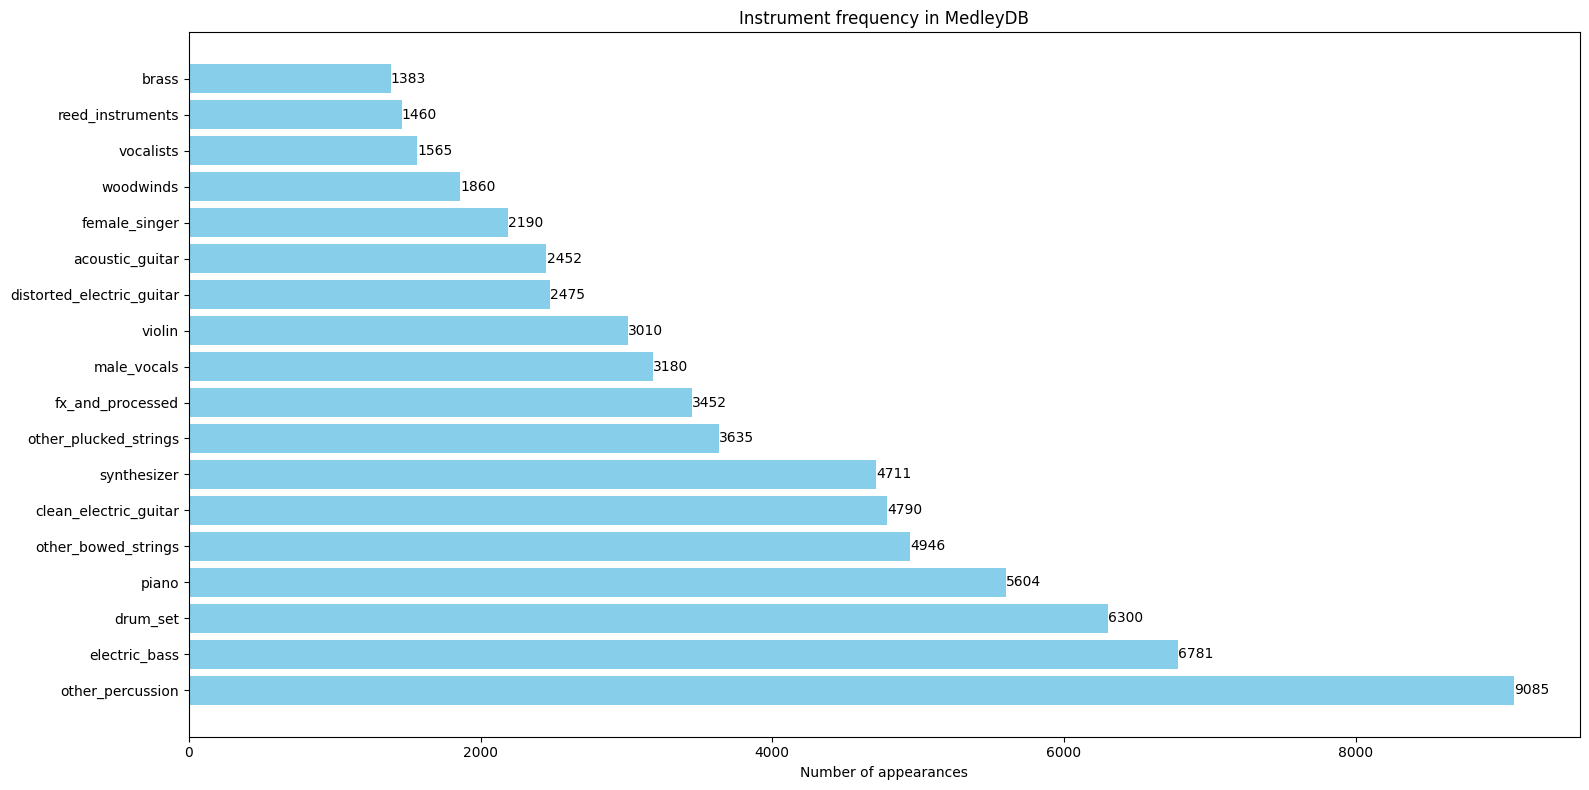


Dataset dimensions:
  Full data: (68879, 96, 130)
  Total number of samples: 68879
  Number of categories: 18


In [6]:
unique_classes, class_counts = np.unique(y, return_counts=True)

# Create a dictionary in the format {instrument: frequency}
instrument_counts = {}
for idx, count in zip(unique_classes, class_counts):
    category_name = instrument_categories[idx]
    instrument_counts[category_name] = count

# Show the distribution
print("\nClass distribution in the complete dataset:")
for category, count in sorted(instrument_counts.items(), key=lambda x: x[1], reverse=True):
    print(f"  {category}: {count} samples ({count/len(y)*100:.1f}%)")

plot_instrument_histogram(instrument_counts, top_n=len(instrument_categories))

print(f"\nDataset dimensions:")
print(f"  Full data: {X.shape}")
print(f"  Total number of samples: {len(y)}")
print(f"  Number of categories: {len(instrument_categories)}")

In [7]:
# Create inverse mapping from index to category name
idx_to_category = {v: k for k, v in category_to_idx.items()}

# Get labels ordered by index
ordered_labels = [idx_to_category[i] for i in range(len(idx_to_category))]
ordered_labels

['electric_bass',
 'drum_set',
 'piano',
 'synthesizer',
 'clean_electric_guitar',
 'distorted_electric_guitar',
 'acoustic_guitar',
 'violin',
 'female_singer',
 'vocalists',
 'male_vocals',
 'other_bowed_strings',
 'woodwinds',
 'brass',
 'other_percussion',
 'other_plucked_strings',
 'reed_instruments',
 'fx_and_processed']

In [9]:
# 2D-CNN model for instrument classification
input_shape = [X_train.shape[1], X_train.shape[2], 1]
num_classes = len(instrument_categories)

model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=input_shape),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

c:\Users\jorge\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 96, 130, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 96, 130, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 65, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 65, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 65, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 24576)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,145,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 18)             │         2,322 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,241,746 (12.37 MB)

 Trainable params: 3,241,298 (12.36 MB)

 Non-trainable params: 448 (1.75 KB)

In [22]:
# Callbacks for training
csv_logger = CSVLogger('training_model_stem.log', append=False)

early_stopping = EarlyStopping(monitor='val_loss', patience=100)

model_name = 'best_model_stem.h5'
model_checkpoint = ModelCheckpoint(model_name, monitor='val_accuracy', save_best_only=True, verbose=1)

callbacks = [csv_logger, early_stopping, model_checkpoint]

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=1000,
    batch_size=32,
    callbacks=callbacks
)

Epoch 1/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 198ms/step - accuracy: 0.3758 - loss: 2.2412
Epoch 1: val_accuracy improved from -inf to 0.63712, saving model to best_model_stem.h5


1722/1722 ━━━━━━━━━━━━━━━━━━━━ 355s 205ms/step - accuracy: 0.3758 - loss: 2.2409 - val_accuracy: 0.6371 - val_loss: 1.0785
Epoch 2/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 199ms/step - accuracy: 0.6644 - loss: 1.0277
Epoch 2: val_accuracy improved from 0.63712 to 0.83631, saving model to best_model_stem.h5


1722/1722 ━━━━━━━━━━━━━━━━━━━━ 354s 206ms/step - accuracy: 0.6644 - loss: 1.0276 - val_accuracy: 0.8363 - val_loss: 0.5343
Epoch 3/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step - accuracy: 0.7734 - loss: 0.6897
Epoch 3: val_accuracy improved from 0.83631 to 0.86077, saving model to best_model_stem.h5


1722/1722 ━━━━━━━━━━━━━━━━━━━━ 351s 204ms/step - accuracy: 0.7735 - loss: 0.6896 - val_accuracy: 0.8608 - val_loss: 0.4332
Epoch 4/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step - accuracy: 0.8202 - loss: 0.5405
Epoch 4: val_accuracy did not improve from 0.86077
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 351s 204ms/step - accuracy: 0.8202 - loss: 0.5405 - val_accuracy: 0.8015 - val_loss: 0.7552
Epoch 5/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step - accuracy: 0.8539 - loss: 0.4478
Epoch 5: val_accuracy improved from 0.86077 to 0.88727, saving model to best_model_stem.h5


1722/1722 ━━━━━━━━━━━━━━━━━━━━ 352s 205ms/step - accuracy: 0.8539 - loss: 0.4478 - val_accuracy: 0.8873 - val_loss: 0.3885
Epoch 6/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step - accuracy: 0.8707 - loss: 0.3980
Epoch 6: val_accuracy did not improve from 0.88727
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 350s 204ms/step - accuracy: 0.8707 - loss: 0.3980 - val_accuracy: 0.8803 - val_loss: 0.4235
Epoch 7/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step - accuracy: 0.8909 - loss: 0.3441
Epoch 7: val_accuracy improved from 0.88727 to 0.92313, saving model to best_model_stem.h5


...

1722/1722 ━━━━━━━━━━━━━━━━━━━━ 362s 210ms/step - accuracy: 0.9663 - loss: 0.1031 - val_accuracy: 0.9604 - val_loss: 0.1664
Epoch 60/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 201ms/step - accuracy: 0.9625 - loss: 0.1149
Epoch 60: val_accuracy did not improve from 0.96037
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 359s 209ms/step - accuracy: 0.9625 - loss: 0.1149 - val_accuracy: 0.9581 - val_loss: 0.1897
Epoch 61/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.9656 - loss: 0.1038
Epoch 61: val_accuracy did not improve from 0.96037
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 362s 210ms/step - accuracy: 0.9656 - loss: 0.1038 - val_accuracy: 0.9541 - val_loss: 0.2167
Epoch 62/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.9662 - loss: 0.1037
Epoch 62: val_accuracy did not improve from 0.96037
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 360s 209ms/step - accuracy: 0.9662 - loss: 0.1037 - val_accuracy: 0.9308 - val_loss: 1.0977
Epoch 63/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.

1722/1722 ━━━━━━━━━━━━━━━━━━━━ 361s 210ms/step - accuracy: 0.9649 - loss: 0.1093 - val_accuracy: 0.9605 - val_loss: 0.1734
Epoch 65/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 201ms/step - accuracy: 0.9654 - loss: 0.1076
Epoch 65: val_accuracy did not improve from 0.96051
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 360s 209ms/step - accuracy: 0.9654 - loss: 0.1076 - val_accuracy: 0.9523 - val_loss: 0.2185
Epoch 66/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.9670 - loss: 0.0990
Epoch 66: val_accuracy did not improve from 0.96051
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 360s 209ms/step - accuracy: 0.9670 - loss: 0.0990 - val_accuracy: 0.9569 - val_loss: 0.2402
Epoch 67/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.9629 - loss: 0.1127
Epoch 67: val_accuracy did not improve from 0.96051
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 361s 210ms/step - accuracy: 0.9629 - loss: 0.1127 - val_accuracy: 0.9548 - val_loss: 0.2551
Epoch 68/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.

1722/1722 ━━━━━━━━━━━━━━━━━━━━ 374s 217ms/step - accuracy: 0.9676 - loss: 0.1008 - val_accuracy: 0.9609 - val_loss: 0.2507
Epoch 93/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - accuracy: 0.9673 - loss: 0.1065
Epoch 93: val_accuracy did not improve from 0.96087
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 364s 212ms/step - accuracy: 0.9673 - loss: 0.1065 - val_accuracy: 0.9584 - val_loss: 0.1800
Epoch 94/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - accuracy: 0.9680 - loss: 0.1016
Epoch 94: val_accuracy did not improve from 0.96087
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 365s 212ms/step - accuracy: 0.9680 - loss: 0.1016 - val_accuracy: 0.7279 - val_loss: 6.3730
Epoch 95/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - accuracy: 0.9660 - loss: 0.1049
Epoch 95: val_accuracy did not improve from 0.96087
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 365s 212ms/step - accuracy: 0.9660 - loss: 0.1049 - val_accuracy: 0.9440 - val_loss: 0.2894
Epoch 96/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step - accuracy: 0.

1722/1722 ━━━━━━━━━━━━━━━━━━━━ 371s 216ms/step - accuracy: 0.9679 - loss: 0.1074 - val_accuracy: 0.9611 - val_loss: 0.2034
Epoch 105/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step - accuracy: 0.9685 - loss: 0.0998
Epoch 105: val_accuracy did not improve from 0.96109
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 366s 213ms/step - accuracy: 0.9685 - loss: 0.0998 - val_accuracy: 0.8587 - val_loss: 4.2234
Epoch 106/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step - accuracy: 0.9672 - loss: 0.1056
Epoch 106: val_accuracy did not improve from 0.96109
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 367s 213ms/step - accuracy: 0.9672 - loss: 0.1056 - val_accuracy: 0.9525 - val_loss: 0.3648
Epoch 107/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 206ms/step - accuracy: 0.9675 - loss: 0.1076
Epoch 107: val_accuracy did not improve from 0.96109
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 368s 214ms/step - accuracy: 0.9675 - loss: 0.1076 - val_accuracy: 0.9570 - val_loss: 0.2007
Epoch 108/1000
1722/1722 ━━━━━━━━━━━━━━━━━━━━ 0s 206ms/step - accur

1722/1722 ━━━━━━━━━━━━━━━━━━━━ 385s 224ms/step - accuracy: 0.9686 - loss: 0.0985 - val_accuracy: 0.9624 - val_loss: 0.2404


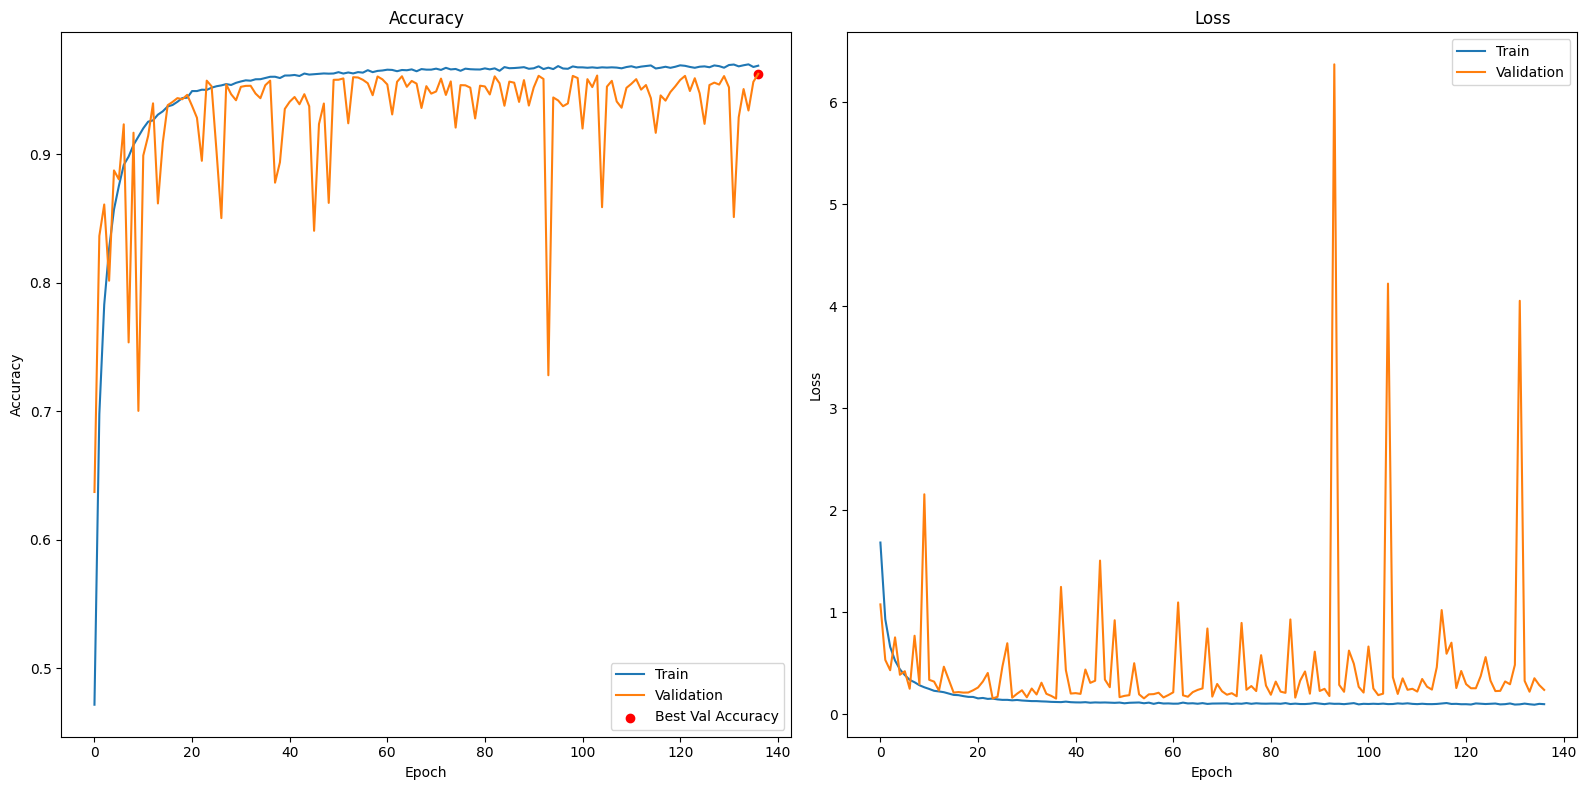

In [38]:
# History plot
log_df = pd.read_csv('training_model_stem.log')
best_val_acc = max(log_df['val_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
model.load_weights('best_model_stem.h5')

388/388 ━━━━━━━━━━━━━━━━━━━━ 17s 40ms/step
216/216 ━━━━━━━━━━━━━━━━━━━━ 17s 81ms/step


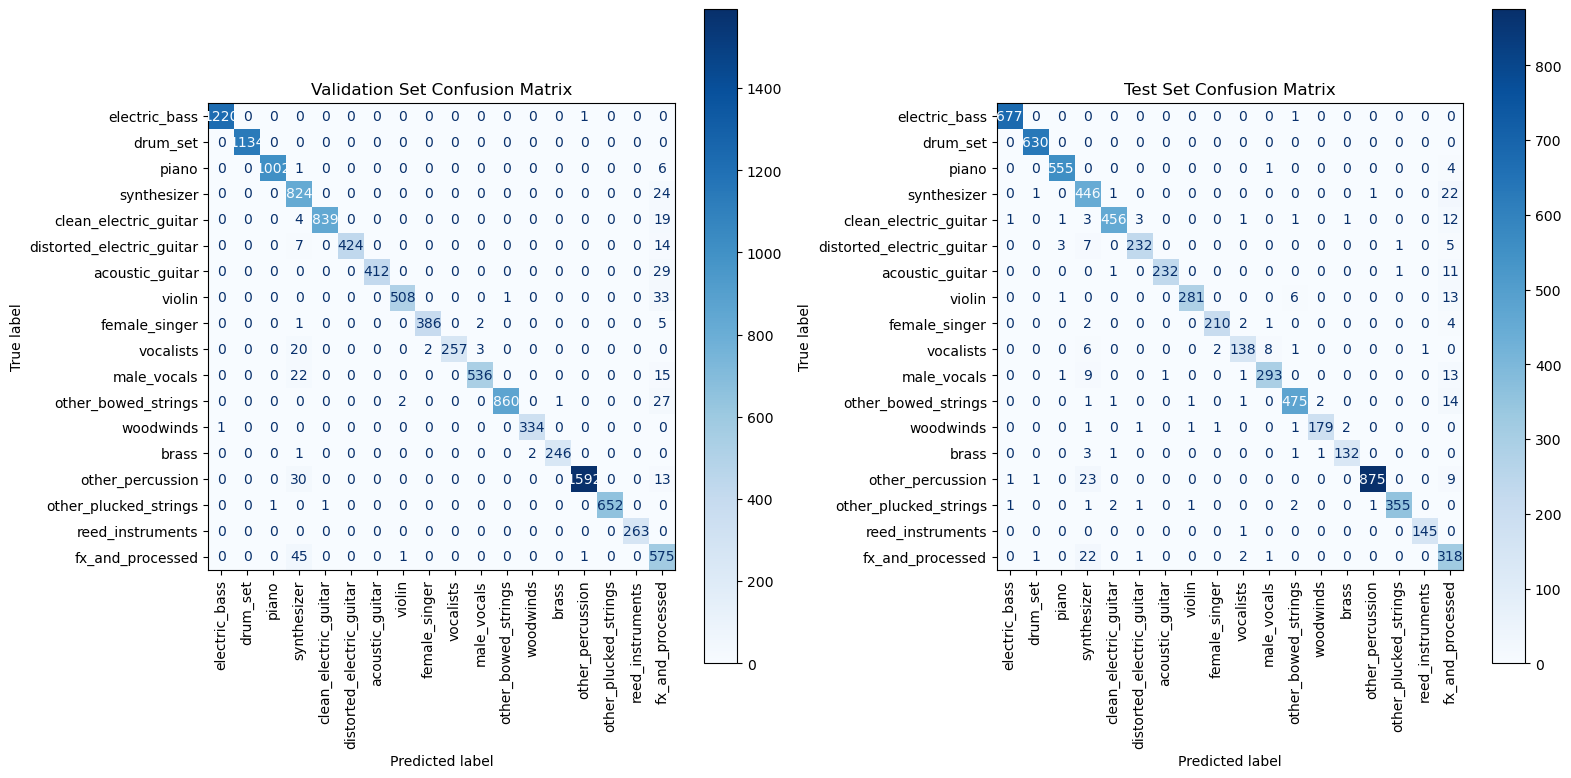

In [ ]:
# Generate predictions
y_val_pred = model.predict(X_val).argmax(axis=1)
y_test_pred = model.predict(X_test).argmax(axis=1)

# Compute confusion matrices
val_cm = confusion_matrix(y_val, y_val_pred)
test_cm = confusion_matrix(y_test, y_test_pred)

# Get ordered category labels
idx_to_category = {v: k for k, v in category_to_idx.items()}
ordered_labels = [idx_to_category[i] for i in range(len(idx_to_category))]

# Plot
plt.figure(figsize=(16, 8))

plt.subplot(1, 2, 1)
ConfusionMatrixDisplay(val_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Validation Set Confusion Matrix")

plt.subplot(1, 2, 2)
ConfusionMatrixDisplay(test_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Test Set Confusion Matrix")

plt.tight_layout()
plt.show()


In [36]:
# Classification report for validation and test sets
print(classification_report(y_val, y_val_pred))
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1221
           1       1.00      1.00      1.00      1134
           2       1.00      0.99      1.00      1009
           3       0.86      0.97      0.91       848
           4       1.00      0.97      0.99       862
           5       1.00      0.95      0.98       445
           6       1.00      0.93      0.97       441
           7       0.99      0.94      0.96       542
           8       0.99      0.98      0.99       394
           9       1.00      0.91      0.95       282
          10       0.99      0.94      0.96       573
          11       1.00      0.97      0.98       890
          12       0.99      1.00      1.00       335
          13       1.00      0.99      0.99       249
          14       1.00      0.97      0.99      1635
          15       1.00      1.00      1.00       654
          16       1.00      1.00      1.00       263
          17       0.76    

# Model 2

In [4]:
X = np.load(os.path.join('extracted_segments_features', 'processed_features_cqt.npy'))  # or cqt
y = np.load(os.path.join('extracted_segments_features', 'processed_labels.npy'))

classes_to_remove = [3, 17]
mask = ~np.isin(y, classes_to_remove)  # Mask to keep only the desired samples

X_filtered = X[mask]
y_filtered = y[mask]

# Create inverse mapping from index to category name
idx_to_category = {v: k for k, v in category_to_idx.items()}

# Get labels ordered by index
ordered_labels = [idx_to_category[i] for i in range(len(idx_to_category))]
ordered_labels

for idx in sorted(classes_to_remove, reverse=True):
    del ordered_labels[idx]


old_to_new = {}
new_idx = 0
for i in range(18):  # original class range
    if i not in classes_to_remove:
        old_to_new[i] = new_idx
        new_idx += 1

# Apply the mapping to y_filtered
y_filtered = np.array([old_to_new[old_label] for old_label in y_filtered])

In [5]:
ordered_labels

['electric_bass',
 'drum_set',
 'piano',
 'clean_electric_guitar',
 'distorted_electric_guitar',
 'acoustic_guitar',
 'violin',
 'female_singer',
 'vocalists',
 'male_vocals',
 'other_bowed_strings',
 'woodwinds',
 'brass',
 'other_percussion',
 'other_plucked_strings',
 'reed_instruments']


Class distribution in the filtered dataset:
  other_percussion: 9085 samples (15.0%)
  electric_bass: 6781 samples (11.2%)
  drum_set: 6300 samples (10.4%)
  piano: 5604 samples (9.2%)
  other_bowed_strings: 4946 samples (8.1%)
  clean_electric_guitar: 4790 samples (7.9%)
  other_plucked_strings: 3635 samples (6.0%)
  male_vocals: 3180 samples (5.2%)
  violin: 3010 samples (5.0%)
  distorted_electric_guitar: 2475 samples (4.1%)
  acoustic_guitar: 2452 samples (4.0%)
  female_singer: 2190 samples (3.6%)
  woodwinds: 1860 samples (3.1%)
  vocalists: 1565 samples (2.6%)
  reed_instruments: 1460 samples (2.4%)
  brass: 1383 samples (2.3%)


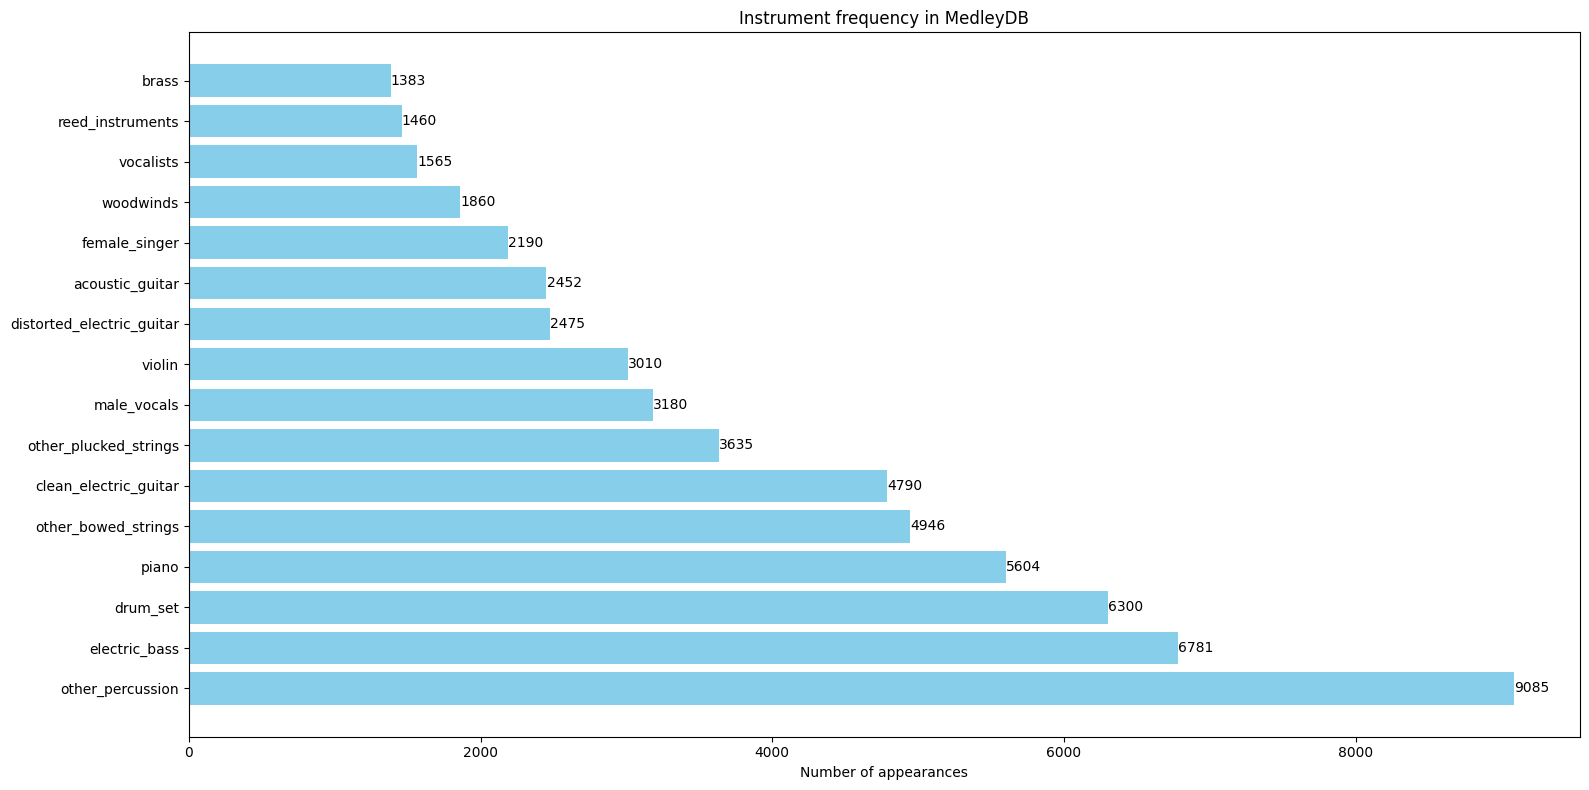


Dataset dimensions:
  Filtered data: (60716, 96, 130)
  Total number of samples: 60716
  Number of categories: 16


In [6]:
# Compute distribution of current class labels
unique_classes, class_counts = np.unique(y_filtered, return_counts=True)

# Create a dictionary: {category_name: count}
category_counts = {}
for idx, count in zip(unique_classes, class_counts):
    category_name = ordered_labels[idx]
    category_counts[category_name] = count

# Show the distribution
print("\nClass distribution in the filtered dataset:")
for category, count in sorted(category_counts.items(), key=lambda x: x[1], reverse=True):
    print(f"  {category}: {count} samples ({count / len(y_filtered) * 100:.1f}%)")

# Plot histogram
plot_instrument_histogram(category_counts, top_n=len(ordered_labels))

# Dataset summary
print(f"\nDataset dimensions:")
print(f"  Filtered data: {X_filtered.shape}")
print(f"  Total number of samples: {len(y_filtered)}")
print(f"  Number of categories: {len(ordered_labels)}")


In [7]:
# Split into train, validation, and test sets
X_temp, X_test, y_temp, y_test = train_test_split(
    X_filtered, y_filtered, test_size=0.1, random_state=42, stratify=y_filtered
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=1.5/9, random_state=42, stratify=y_temp
)

print(f"Loaded data: {X_filtered.shape}")

Loaded data: (60716, 96, 130)


In [8]:
# Only on training set
mean = np.mean(X_train)
std = np.std(X_train)

X_train = (X_train - mean) / (std + 1e-6)
X_val = (X_val - mean) / (std + 1e-6)
X_test = (X_test - mean) / (std + 1e-6)

In [9]:
input_shape = (96, 130, 1)
num_classes = len(ordered_labels)

model = models.Sequential([
    layers.Conv2D(16, (3, 3), activation='relu', padding='same', input_shape=input_shape),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

c:\Users\Giuliano\Documents\STMAE\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 96, 130, 16)    │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 96, 130, 16)    │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 65, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 65, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 65, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       786,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │         1,040 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 811,280 (3.09 MB)

 Trainable params: 811,056 (3.09 MB)

 Non-trainable params: 224 (896.00 B)

In [14]:
# Callbacks for training
csv_logger = CSVLogger('training_model_stem_small_cqt.log', append=False)

early_stopping = EarlyStopping(monitor='val_loss', patience=20)

model_name = 'best_model_stem_small_cqt.h5'
model_checkpoint = ModelCheckpoint(model_name, monitor='val_accuracy', save_best_only=True, verbose=1)

callbacks = [csv_logger, early_stopping, model_checkpoint]

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=200,
    batch_size=32,
    callbacks=callbacks
)

Epoch 1/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.4057 - loss: 1.9220
Epoch 1: val_accuracy improved from -inf to 0.71157, saving model to best_model_stem_small_cqt.h5


1423/1423 ━━━━━━━━━━━━━━━━━━━━ 122s 85ms/step - accuracy: 0.4057 - loss: 1.9218 - val_accuracy: 0.7116 - val_loss: 0.8706
Epoch 2/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.6137 - loss: 1.1032
Epoch 2: val_accuracy improved from 0.71157 to 0.79161, saving model to best_model_stem_small_cqt.h5


1423/1423 ━━━━━━━━━━━━━━━━━━━━ 120s 84ms/step - accuracy: 0.6138 - loss: 1.1032 - val_accuracy: 0.7916 - val_loss: 0.6221
Epoch 3/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.7027 - loss: 0.8469
Epoch 3: val_accuracy improved from 0.79161 to 0.81983, saving model to best_model_stem_small_cqt.h5


1423/1423 ━━━━━━━━━━━━━━━━━━━━ 120s 84ms/step - accuracy: 0.7027 - loss: 0.8469 - val_accuracy: 0.8198 - val_loss: 0.5632
Epoch 4/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.7585 - loss: 0.6823
Epoch 4: val_accuracy improved from 0.81983 to 0.87769, saving model to best_model_stem_small_cqt.h5


1423/1423 ━━━━━━━━━━━━━━━━━━━━ 121s 85ms/step - accuracy: 0.7585 - loss: 0.6823 - val_accuracy: 0.8777 - val_loss: 0.3774
Epoch 5/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.8070 - loss: 0.5497
Epoch 5: val_accuracy improved from 0.87769 to 0.88922, saving model to best_model_stem_small_cqt.h5


...

1423/1423 ━━━━━━━━━━━━━━━━━━━━ 121s 85ms/step - accuracy: 0.9644 - loss: 0.1094 - val_accuracy: 0.9639 - val_loss: 0.1425
Epoch 35/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9671 - loss: 0.0983
Epoch 35: val_accuracy did not improve from 0.96388
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 120s 84ms/step - accuracy: 0.9671 - loss: 0.0983 - val_accuracy: 0.9543 - val_loss: 0.1908
Epoch 36/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9663 - loss: 0.1008
Epoch 36: val_accuracy did not improve from 0.96388
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 121s 85ms/step - accuracy: 0.9663 - loss: 0.1008 - val_accuracy: 0.9564 - val_loss: 0.1501
Epoch 37/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9662 - loss: 0.1033
Epoch 37: val_accuracy did not improve from 0.96388
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 121s 85ms/step - accuracy: 0.9662 - loss: 0.1033 - val_accuracy: 0.9629 - val_loss: 0.1303
Epoch 38/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9661 - loss:

1423/1423 ━━━━━━━━━━━━━━━━━━━━ 121s 85ms/step - accuracy: 0.9661 - loss: 0.0967 - val_accuracy: 0.9643 - val_loss: 0.1431
Epoch 39/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9677 - loss: 0.0925
Epoch 39: val_accuracy did not improve from 0.96432
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 120s 85ms/step - accuracy: 0.9677 - loss: 0.0925 - val_accuracy: 0.9570 - val_loss: 0.1597
Epoch 40/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9689 - loss: 0.0922
Epoch 40: val_accuracy did not improve from 0.96432
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 121s 85ms/step - accuracy: 0.9689 - loss: 0.0922 - val_accuracy: 0.9628 - val_loss: 0.1456
Epoch 41/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9684 - loss: 0.0953
Epoch 41: val_accuracy did not improve from 0.96432
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 121s 85ms/step - accuracy: 0.9683 - loss: 0.0954 - val_accuracy: 0.9614 - val_loss: 0.1566
Epoch 42/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9698 - loss:

1423/1423 ━━━━━━━━━━━━━━━━━━━━ 123s 86ms/step - accuracy: 0.9701 - loss: 0.0874 - val_accuracy: 0.9644 - val_loss: 0.1588
Epoch 50/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9726 - loss: 0.0791
Epoch 50: val_accuracy did not improve from 0.96443
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 120s 85ms/step - accuracy: 0.9726 - loss: 0.0791 - val_accuracy: 0.9642 - val_loss: 0.1348
Epoch 51/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9721 - loss: 0.0840
Epoch 51: val_accuracy did not improve from 0.96443
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 120s 85ms/step - accuracy: 0.9721 - loss: 0.0840 - val_accuracy: 0.9634 - val_loss: 0.1560
Epoch 52/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.9733 - loss: 0.0822
Epoch 52: val_accuracy improved from 0.96443 to 0.96476, saving model to best_model_stem_small_cqt.h5


1423/1423 ━━━━━━━━━━━━━━━━━━━━ 121s 85ms/step - accuracy: 0.9733 - loss: 0.0822 - val_accuracy: 0.9648 - val_loss: 0.1490
Epoch 53/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9717 - loss: 0.0820
Epoch 53: val_accuracy improved from 0.96476 to 0.96981, saving model to best_model_stem_small_cqt.h5


1423/1423 ━━━━━━━━━━━━━━━━━━━━ 120s 85ms/step - accuracy: 0.9717 - loss: 0.0820 - val_accuracy: 0.9698 - val_loss: 0.1322
Epoch 54/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9731 - loss: 0.0803
Epoch 54: val_accuracy did not improve from 0.96981
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 121s 85ms/step - accuracy: 0.9731 - loss: 0.0803 - val_accuracy: 0.9641 - val_loss: 0.1403
Epoch 55/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9715 - loss: 0.0805
Epoch 55: val_accuracy did not improve from 0.96981
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 121s 85ms/step - accuracy: 0.9715 - loss: 0.0805 - val_accuracy: 0.9617 - val_loss: 0.1545
Epoch 56/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.9730 - loss: 0.0765
Epoch 56: val_accuracy did not improve from 0.96981
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 121s 85ms/step - accuracy: 0.9730 - loss: 0.0765 - val_accuracy: 0.9629 - val_loss: 0.1312
Epoch 57/200
1423/1423 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.9729 - loss:

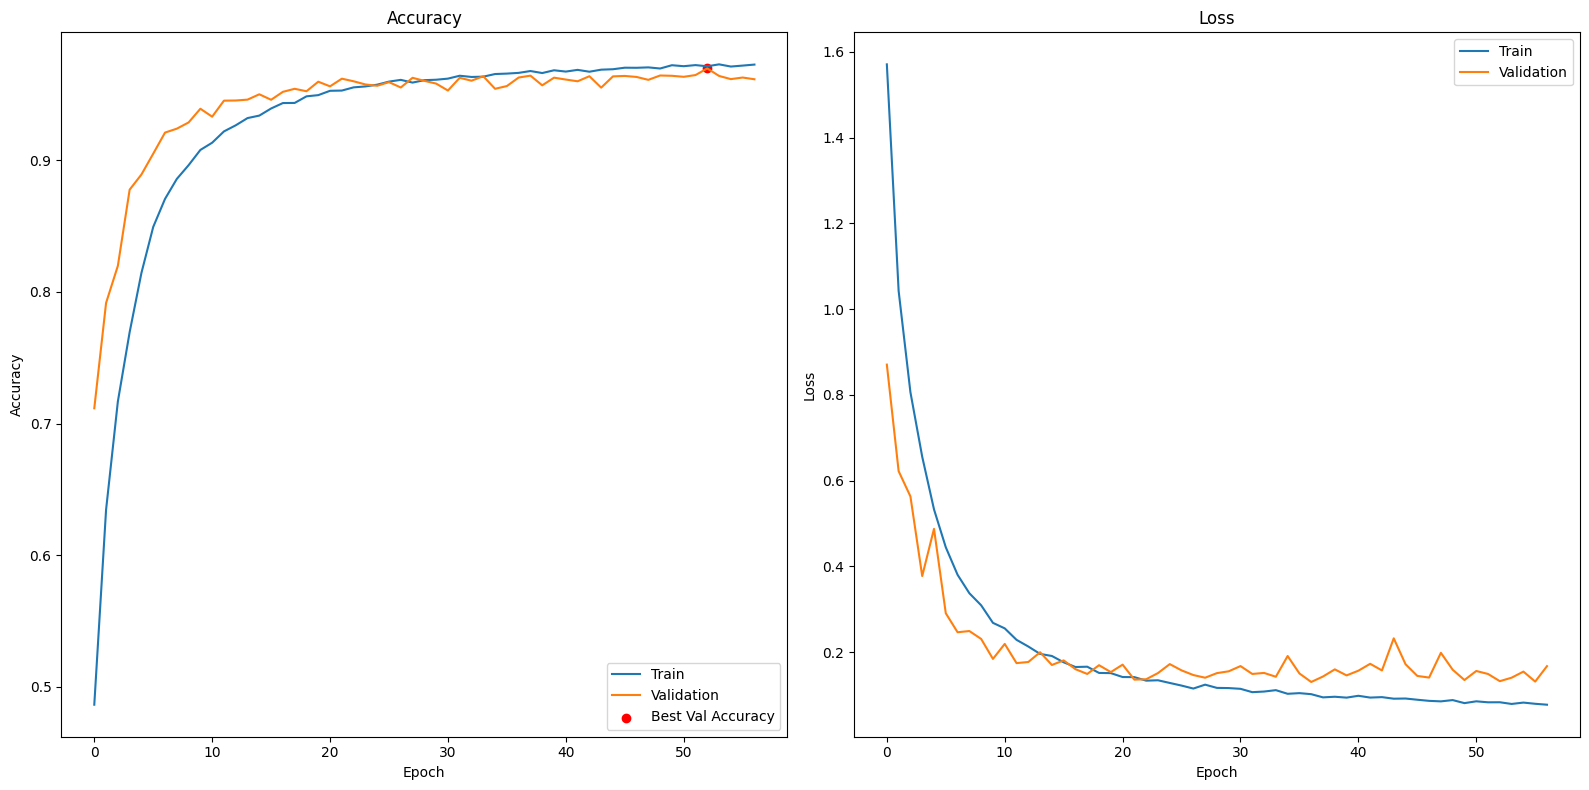

In [10]:
# History plot
log_df = pd.read_csv('training_model_stem_small_cqt.log')
best_val_acc = max(log_df['val_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
model.load_weights('best_model_stem_small_cqt.h5')

285/285 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step
190/190 ━━━━━━━━━━━━━━━━━━━━ 7s 35ms/step


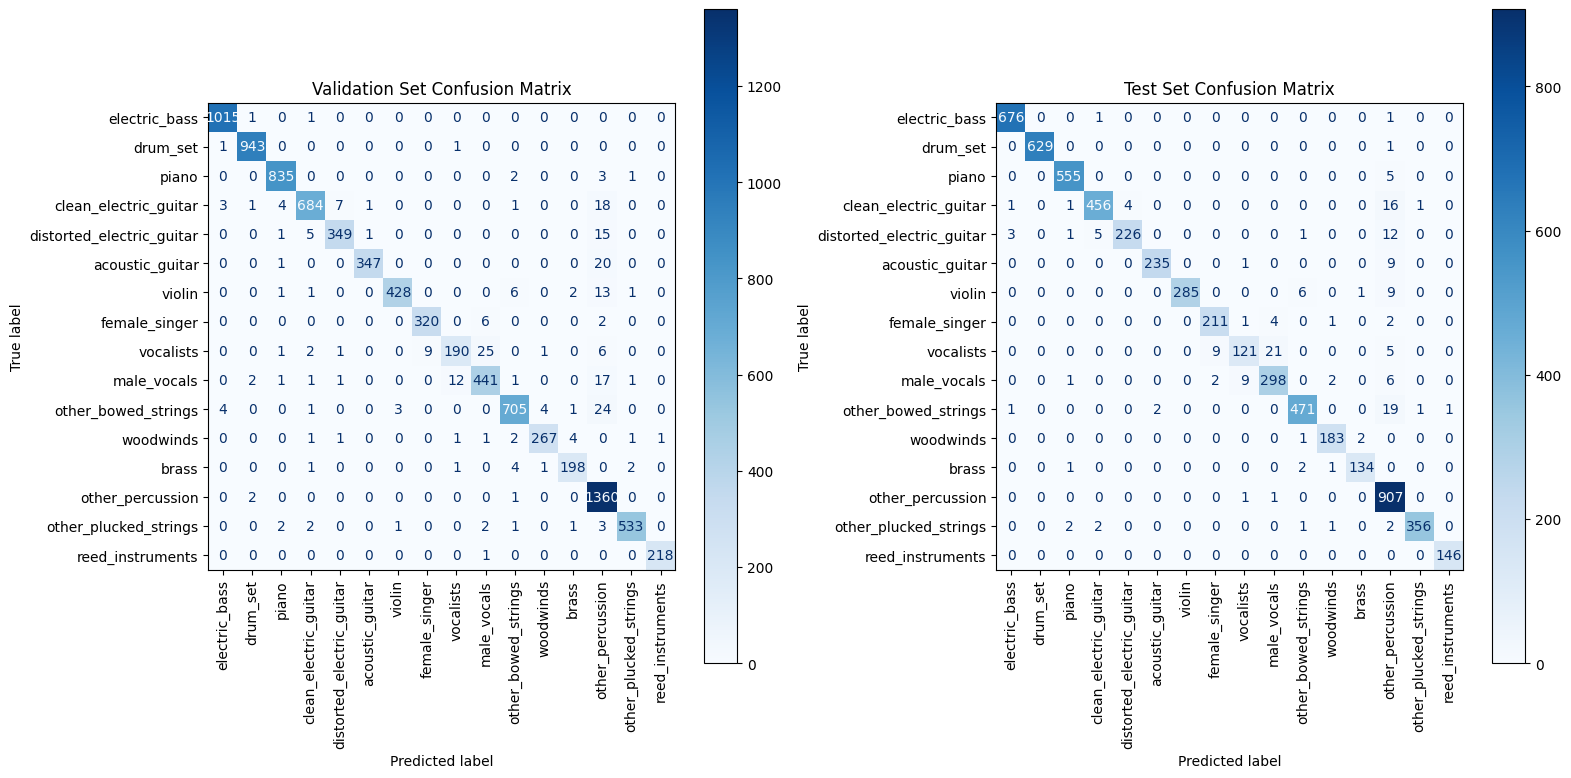

In [15]:
# Predict class probabilities
y_val_pred_prob = model.predict(X_val)
y_test_pred_prob = model.predict(X_test)

# Get predicted class indices
y_val_pred = y_val_pred_prob.argmax(axis=1)
y_test_pred = y_test_pred_prob.argmax(axis=1)

# Compute confusion matrices
val_cm = confusion_matrix(y_val, y_val_pred)
test_cm = confusion_matrix(y_test, y_test_pred)

# Plot confusion matrices
plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
ConfusionMatrixDisplay(val_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Validation Set Confusion Matrix")
plt.subplot(1, 2, 2)
ConfusionMatrixDisplay(test_cm, display_labels=ordered_labels).plot(cmap='Blues', ax=plt.gca(), xticks_rotation=90)
plt.title("Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

In [16]:
# For classification report
print(classification_report(y_val, y_val_pred, target_names=ordered_labels))
print(classification_report(y_test, y_test_pred, target_names=ordered_labels))

                           precision    recall  f1-score   support

            electric_bass       0.99      1.00      1.00      1017
                 drum_set       0.99      1.00      1.00       945
                    piano       0.99      0.99      0.99       841
    clean_electric_guitar       0.98      0.95      0.96       719
distorted_electric_guitar       0.97      0.94      0.96       371
          acoustic_guitar       0.99      0.94      0.97       368
                   violin       0.99      0.95      0.97       452
            female_singer       0.97      0.98      0.97       328
                vocalists       0.93      0.81      0.86       235
              male_vocals       0.93      0.92      0.93       477
      other_bowed_strings       0.98      0.95      0.96       742
                woodwinds       0.98      0.96      0.97       279
                    brass       0.96      0.96      0.96       207
         other_percussion       0.92      1.00      0.96     